# EDA: storm overflow spills and rain

Looks at the data behind the model: when spills happen, how strongly they follow
rain, and what one storm looks like at one overflow. Run
`scripts/fetch_data.py` and `scripts/build_features.py` first.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from triton.constants import PROCESSED_DIR, RAW_DIR
from triton.features import target_name

BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"
plt.rcParams.update(
    {
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.edgecolor": MUTED,
        "axes.labelcolor": INK,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "axes.grid": True,
        "axes.axisbelow": True,
        "grid.color": "#e6e5e0",
        "figure.dpi": 110,
    }
)
TARGET = target_name(6)

sites = pd.read_csv(RAW_DIR / "sites_selected.csv.gz")
episodes = pd.read_csv(PROCESSED_DIR / "episodes.csv.gz", parse_dates=["start", "end"])
rain = pd.read_csv(RAW_DIR / "rain_hourly.csv.gz", parse_dates=["timestamp"])
panel = pd.read_csv(PROCESSED_DIR / "model_table.csv.gz", parse_dates=["timestamp"])
print(
    f"{len(sites)} overflows, {len(episodes)} spill episodes, {len(panel)} hourly rows"
)

40 overflows, 4355 spill episodes, 948240 hourly rows


## The overflows
The 40 with the most spills that report in every year since 2024.

In [2]:
sites[["site_id", "name", "river", "n_events"]].head(10)

,site_id,name,river,n_events
0,TWL00093,Chinnor,Henton Stream,3251
1,TWL00452,Windsor,River Thames,2695
2,TWL00319,St Stephens Hall (Little London),Bow Brook,1372
3,TWL00309,Newbury,River Kennet,912
4,TWL00181,Farnborough (Warks),Tributary of Hanwell Brook,859
5,TWL00061,Bucklebury (Briff Lane),Briff Lane Stream,672
6,TWL00378,South Moreton,Mill Brook,655
7,TWL00024,Bampton,Shill Brook,652
8,TWL00369,Shutford,Shutford Stream,617
9,TWL00425,Wantage,Letcombe Brook,579


## Spills are seasonal
Spill episodes (flicker under 6 hours merged) started per month, all 40 overflows.

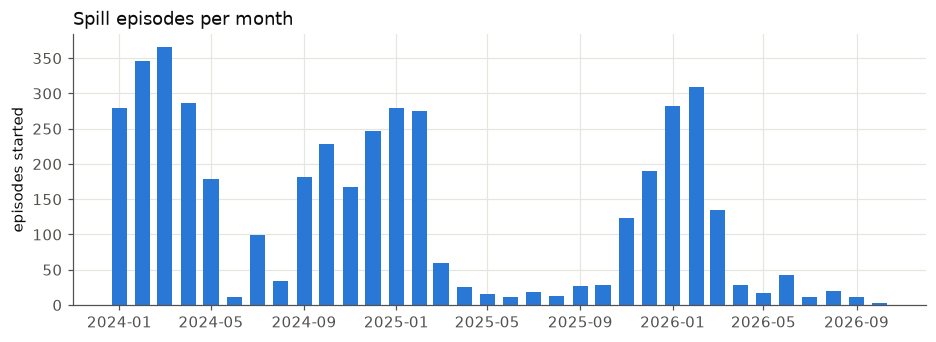

In [3]:
per_month = episodes.set_index("start").resample("MS").size()
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.bar(per_month.index, per_month.values, width=20, color=BLUE)
ax.set_ylabel("episodes started")
ax.set_title("Spill episodes per month", loc="left", color=INK)
plt.show()

## Spills follow rain

Chance that a new spill starts in the next 6 hours, for hours when the overflow
is not already spilling, by how much rain fell in the previous 24 hours and the
previous 30 days. The 30 day total stands in for how wet the ground is.

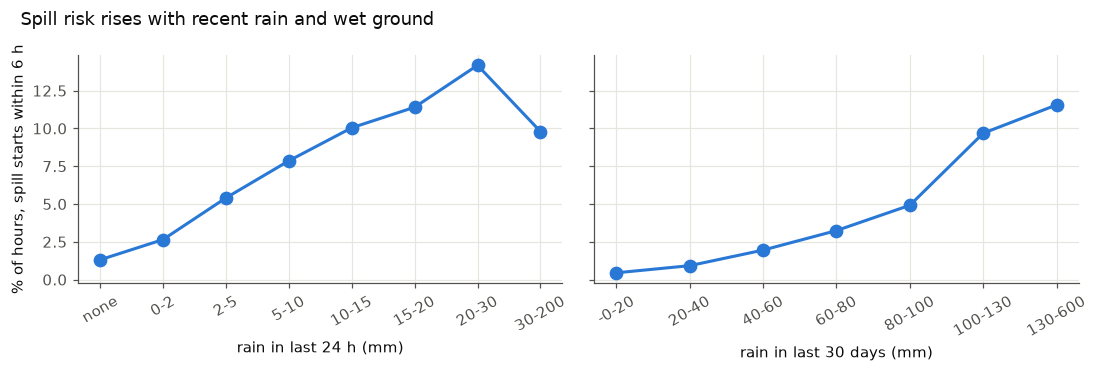

Base rate: 2.96% of non-spilling hours have a spill within 6h


In [4]:
dry = panel[panel["spilling_now"] == 0]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for ax, col, bins, label in [
    (
        axes[0],
        "rain_24h",
        [0, 0.1, 2, 5, 10, 15, 20, 30, 200],
        "rain in last 24 h (mm)",
    ),
    (
        axes[1],
        "rain_30d",
        [0, 20, 40, 60, 80, 100, 130, 600],
        "rain in last 30 days (mm)",
    ),
]:
    grouped = dry.groupby(pd.cut(dry[col], bins, include_lowest=True), observed=True)
    rate = grouped[TARGET].mean() * 100
    names = [
        "none" if b.right <= 0.1 else f"{b.left:.0f}-{b.right:.0f}" for b in rate.index
    ]
    ax.plot(names, rate.values, color=BLUE, linewidth=2, marker="o", markersize=8)
    ax.set_xlabel(label)
    ax.tick_params(axis="x", rotation=30)
axes[0].set_ylabel("% of hours, spill starts within 6 h")
fig.suptitle(
    "Spill risk rises with recent rain and wet ground", x=0.01, ha="left", color=INK
)
plt.tight_layout()
plt.show()
print(
    f"Base rate: {dry[TARGET].mean():.2%} of non-spilling hours have a spill within 6h"
)

## Class balance

In [5]:
balance = panel.groupby(panel["timestamp"].dt.year)[TARGET].agg(
    rows="size", positive="mean"
)
balance["positive"] = (balance["positive"] * 100).round(2).astype(str) + "%"
balance

,rows,positive
timestamp,,
2024,322560,4.0%
2025,350400,1.83%
2026,275280,1.88%


## One storm at one overflow
The busiest week of 2026 at the overflow with the most episodes that year.

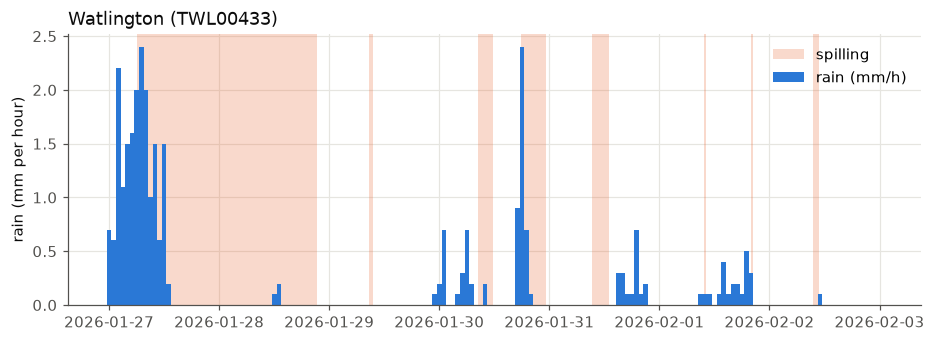

In [6]:
recent = episodes[episodes["start"] >= "2026-01-01"]
site = recent["site_id"].value_counts().index[0]
name = sites.set_index("site_id").loc[site, "name"]
week_start = recent[recent["site_id"] == site]["start"].dt.floor(
    "D"
).value_counts().index[0] - pd.Timedelta(days=3)
week_end = week_start + pd.Timedelta(days=7)

r = rain[(rain["site_id"] == site) & rain["timestamp"].between(week_start, week_end)]
ep = episodes[
    (episodes["site_id"] == site)
    & (episodes["end"] >= week_start)
    & (episodes["start"] <= week_end)
]

fig, ax = plt.subplots(figsize=(10, 3.2))
for i, e in enumerate(ep.itertuples()):
    ax.axvspan(
        e.start,
        e.end,
        color=ORANGE,
        alpha=0.25,
        linewidth=0,
        label="spilling" if i == 0 else None,
    )
ax.bar(r["timestamp"], r["rain_mm"], width=1 / 24, color=BLUE, label="rain (mm/h)")
ax.set_ylabel("rain (mm per hour)")
ax.set_title(f"{name} ({site})", loc="left", color=INK)
ax.legend(frameon=False, loc="upper right")
plt.show()